# БЕЛОРУССКИЙ ГОСУДАРСТВЕННЫЙ УНИВЕРСИТЕТ ИНФОРМАТИКИ И РАДИОЭЛЕКТРОНИКИ
## Факультет компьютерных систем и сетей
### Кафедра программного обеспечения информационных технологий

---
**Дисциплина:** Методы машинного обучения (ММО)  
**Лабораторная работа № 4:** «Бинарная классификация данных: Логистическая регрессия, Метод опорных векторов (SVM), Деревья решений (CART)»  
**Выполнила:** студентка группы 351002 Алексейчик Яна Николаевна  
**Преподаватель:** доцент кафедры ПОИТ Лебедевич А. В.  
**Используемый датасет:** Healthy Meal Plan Dataset (`healthy_meal_plans.csv`)  
**Теоретическая база:** Материалы лекционного курса кафедры ПОИТ (Лекция 08 «Классификация. Логистическая регрессия. Метод опорных векторов», Лекция 09 «Деревья принятия решений»)  
**Год выполнения:** 2026  
---

## 📑 Оглавление
1. [Теоретические основы и математический аппарат лекционного курса](#1.-Теоретические-основы-и-математический-аппарат-лекционного-курса)
2. [Импорт библиотек и глобальные настройки среды](#2.-Импорт-библиотек-и-глобальные-настройки-среды)
3. [Загрузка данных, первичный анализ (EDA) и обнаружение дисбаланса](#3.-Загрузка-данных,-первичный-анализ-(EDA)-и-обнаружение-дисбаланса)
4. [Предобработка данных и защита от утечек (Data Leakage)](#4.-Предобработка-данных-и-защита-от-утечек-(Data-Leakage))
5. [Модель 1: Логистическая регрессия с нуля (Custom Logistic Regression) и эталон Sklearn](#5.-Модель-1:-Логистическая-регрессия-с-нуля-(Custom-Logistic-Regression)-и-эталон-Sklearn)
6. [Модель 2: Метод опорных векторов (SVM) с нуля и ядерный SVM Scikit-Learn](#6.-Модель-2:-Метод-опорных-векторов-(SVM)-с-нуля-и-ядерный-SVM-Scikit-Learn)
7. [Модель 3: Деревья принятия решений (CART) с нуля и эталон Sklearn](#7.-Модель-3:-Деревья-принятия-решений-(CART)-с-нуля-и-эталон-Sklearn)
8. [Исследование регуляризации и переобучения дерева решений (max_depth)](#8.-Исследование-регуляризации-и-переобучения-дерева-решений-(max_depth))
9. [Сравнительный бенчмарк моделей, матрицы ошибок и анализ кривых ROC-AUC / PR-AUC](#9.-Сравнительный-бенчмарк-моделей,-матрицы-ошибок-и-анализ-кривых-ROC-AUC-/-PR-AUC)
10. [Итоговые выводы и контрольные вопросы к защите лабораторной работы](#10.-Итоговые-выводы-и-контрольные-вопросы-к-защите-лабораторной-работы)

---

## 🎯 Требования официального задания кафедры ПОИТ
1. **Импорт данных:** Импортировать датасет для бинарной классификации (целевой признак бинарный $\{0, 1\}$).
2. **Очистка и масштабирование:** Очистить датасет от пропусков и выбросов (если есть), выполнить нормализацию либо стандартизацию данных.
3. **Формирование выборки:** Выбрать целевую переменную и сформировать признаковое пространство.
4. **Построение моделей:** Создать модели бинарной классификации на основе логистической регрессии, метода опорных векторов (SVM) и деревьев решений (CART).
5. **Оценка качества:** Оценить качество моделей с помощью комплексного набора метрик (Accuracy, Precision, Recall, F1, ROC-AUC, PR-AUC, Confusion Matrix).

## 1. Теоретические основы и математический аппарат лекционного курса

### 1.1 Логистическая регрессия (Logistic Regression)
В задаче бинарной классификации объекты $x \in \mathbb{R}^m$ относятся к одному из классов $y \in \{0, 1\}$. Модель логистической регрессии оценивает апостериорную вероятность принадлежности объекта к положительному классу:
$$P(y = 1 \mid x) = \sigma(z) = \frac{1}{1 + e^{-z}}, \quad z = w^T x + w_0$$
где $\sigma(z)$ — логистическая (сигмоидная) функция активации, переводящая произвольное значение вещественной оси в диапазон $(0, 1)$.

Функцией потерь является **логарифмическая функция потерь (Log Loss / бинарная кросс-энтропия)**:
$$\mathcal{L}(w) = -\frac{1}{l} \sum_{i=1}^l \left[ y_i \ln(\sigma(w^T x_i)) + (1 - y_i) \ln(1 - \sigma(w^T x_i)) \right]$$

Градиент функции потерь по вектору весов имеет строгую векторизованную форму:
$$\nabla_w \mathcal{L}(w) = \frac{1}{l} X^T (\sigma(X w) - y)$$

Для предотвращения переобучения применяется $L_2$-регуляризация (свободный член $w_0$ не штрафуется):
$$\mathcal{L}_{reg}(w) = \mathcal{L}(w) + \frac{\lambda}{2l} \|w_{1:m}\|_2^2, \quad \nabla_w \mathcal{L}_{reg}(w) = \nabla_w \mathcal{L}(w) + \frac{\lambda}{l} \begin{bmatrix} 0 \\ w_{1:m} \end{bmatrix}$$

---

### 1.2 Метод опорных векторов (Support Vector Machine, SVM)
Метод опорных векторов строит разделяющую гиперплоскость $w^T x + b = 0$, обеспечивающую **максимальный геометрический зазор (margin)** между классами:
$$\text{Margin} = \frac{2}{\|w\|_2}$$

При наличии линейной неразделимости или шума задача оптимизируется в форме «мягкого зазора» (Soft Margin) через функцию потерь **Hinge Loss**:
$$\min_{w, b} \left( \frac{1}{2} \|w\|_2^2 + C \sum_{i=1}^l \max\left(0, 1 - y_i (w^T x_i + b)\right) \right), \quad y_i \in \{-1, +1\}$$
где параметр $C > 0$ определяет баланс между максимизацией ширины зазора и штрафом за ошибки классификации. Для нелинейных данных применяется ядровый трюк (Kernel Trick), например, радиальная базисная функция (RBF):
$$K(x, x') = \exp\left(-\gamma \|x - x'\|^2\right)$$

---

### 1.3 Деревья принятия решений (CART)
Алгоритм CART (Classification and Regression Trees) рекурсивно разбивает пространство признаков на непересекающиеся гиперпрямоугольники с помощью предикатов вида $[x_j \le t]$.

Функционалом качества разбиения множества $X_m$ на левое $X_l$ и правое $X_r$ поддеревья является **прирост информации (Information Gain)**:
$$Q(X_m, j, t) = H(X_m) - \frac{|X_l|}{|X_m|} H(X_l) - \frac{|X_r|}{|X_m|} H(X_r) \to \max_{j, t}$$

В качестве критерия информативности $H(X)$ используются:
1. **Индекс неопределенности Джини (Gini Impurity):**
   $$G(X) = 1 - \sum_{k=0}^1 p_k^2 = 2 p_0 p_1$$
2. **Энтропия Шеннона (Shannon Entropy):**
   $$H(X) = -\sum_{k=0}^1 p_k \log_2(p_k)$$
где $p_k = \frac{1}{|X|} \sum_{i \in X} [y_i = k]$ — эмпирическая доля объектов класса $k$.

---

### 1.4 Комплексные метрики качества и проблема дисбаланса
При несбалансированных выборках метрика точности (Accuracy) не отражает качество модели: константный классификатор большинства получает высокий Accuracy при нулевой полезности. Поэтому рассчитывается расширенная система метрик:
- **Матрица ошибок (Confusion Matrix):** $TP, FP, FN, TN$.
- **Точность (Precision):** $\text{Precision} = \frac{TP}{TP + FP}$ — уверенность в положительном ответе.
- **Полнота (Recall / Sensitivity):** $\text{Recall} = \frac{TP}{TP + FN}$ — способность обнаружить объекты целевого класса.
- **F1-мера (F1-Score):** $F_1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$ — гармоническое среднее точности и полноты.
- **ROC-AUC (Receiver Operating Characteristic):** площадь под кривой зависимости $TPR(FPR)$, отражает ранжирующую способность модели независимо от порога отсечения.
- **PR-AUC (Precision-Recall Curve):** площадь под кривой точность-полнота, наиболее чувствительная к целевому редкому классу.

In [1]:
# 2. Импорт библиотек и глобальные настройки среды
import sys
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    classification_report
)

warnings.filterwarnings("ignore")

# Настройки оформления графиков публикационного качества (300 DPI)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "figure.titlesize": 14,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.dpi": 300,
    "savefig.dpi": 300
})

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Библиотеки успешно импортированы. Среда настроена (seed=42).")

Библиотеки успешно импортированы. Среда настроена (seed=42).


## 3. Загрузка данных, первичный анализ (EDA) и обнаружение дисбаланса
Загружаем исследуемый датасет `healthy_meal_plans.csv` из каталога `Задание`.
Датасет содержит характеристики блюд: количество ингредиентов, калорийность, время приготовления, макронутриенты (белки, жиры, углеводы), признаки принадлежности к различным диетам (веганская, вегетарианская, кето, палео, безглютеновая, средиземноморская), а также целевой признак **`is_healthy`** (1 — здоровое блюдо, 0 — нездоровое).

In [2]:
# Определение пути к файлу датасета
current_dir = Path(os.getcwd())
data_path = current_dir / "Задание" / "Healthy Meal Plan Dataset" / "Healthy Meal Plan Dataset" / "healthy_meal_plans.csv"
if not data_path.exists():
    data_path = current_dir.parent / "Задание" / "Healthy Meal Plan Dataset" / "Healthy Meal Plan Dataset" / "healthy_meal_plans.csv"

raw_df = pd.read_csv(data_path)
print(f"Размерность исходного набора данных: {raw_df.shape[0]} строк, {raw_df.shape[1]} признаков.")
print("\nПервые 5 строк таблицы:")
raw_df.head()

Размерность исходного набора данных: 500 строк, 14 признаков.

Первые 5 строк таблицы:


,meal_name,num_ingredients,calories,prep_time,protein,fat,carbs,vegan,vegetarian,keto,paleo,gluten_free,mediterranean,is_healthy
0,Gluten-Free Pasta,0.272727,0.490909,0.84,0.783679,0.597907,0.444572,0,0,0,0,1,0,1
1,Grilled Salmon,0.909091,0.158182,0.70,0.143588,0.652082,0.050609,0,0,1,1,1,1,0
2,Lentil Soup,0.454545,0.700000,0.40,0.620637,0.612748,0.000688,0,1,0,0,0,0,0
3,Chickpea Stew,0.909091,0.105455,0.82,0.046893,0.975761,0.229026,1,1,0,0,0,0,0
4,Turkey Lettuce Wraps,0.181818,0.441818,0.04,0.864340,0.681575,0.449293,0,0,1,1,1,1,0


In [3]:
# Анализ пропущенных значений и типов данных
print("Пропущенные значения по столбцам:")
print(raw_df.isnull().sum())

print("\nРаспределение целевой переменной is_healthy:")
target_counts = raw_df["is_healthy"].value_counts()
target_prop = raw_df["is_healthy"].value_counts(normalize=True) * 100
for cls, count in target_counts.items():
    print(f"Класс {cls}: {count} объектов ({target_prop[cls]:.2f}%)")

Пропущенные значения по столбцам:
meal_name          0
num_ingredients    0
calories           0
prep_time          0
protein            0
fat                0
carbs              0
vegan              0
vegetarian         0
keto               0
paleo              0
gluten_free        0
mediterranean      0
is_healthy         0
dtype: int64

Распределение целевой переменной is_healthy:
Класс 0: 453 объектов (90.60%)
Класс 1: 47 объектов (9.40%)


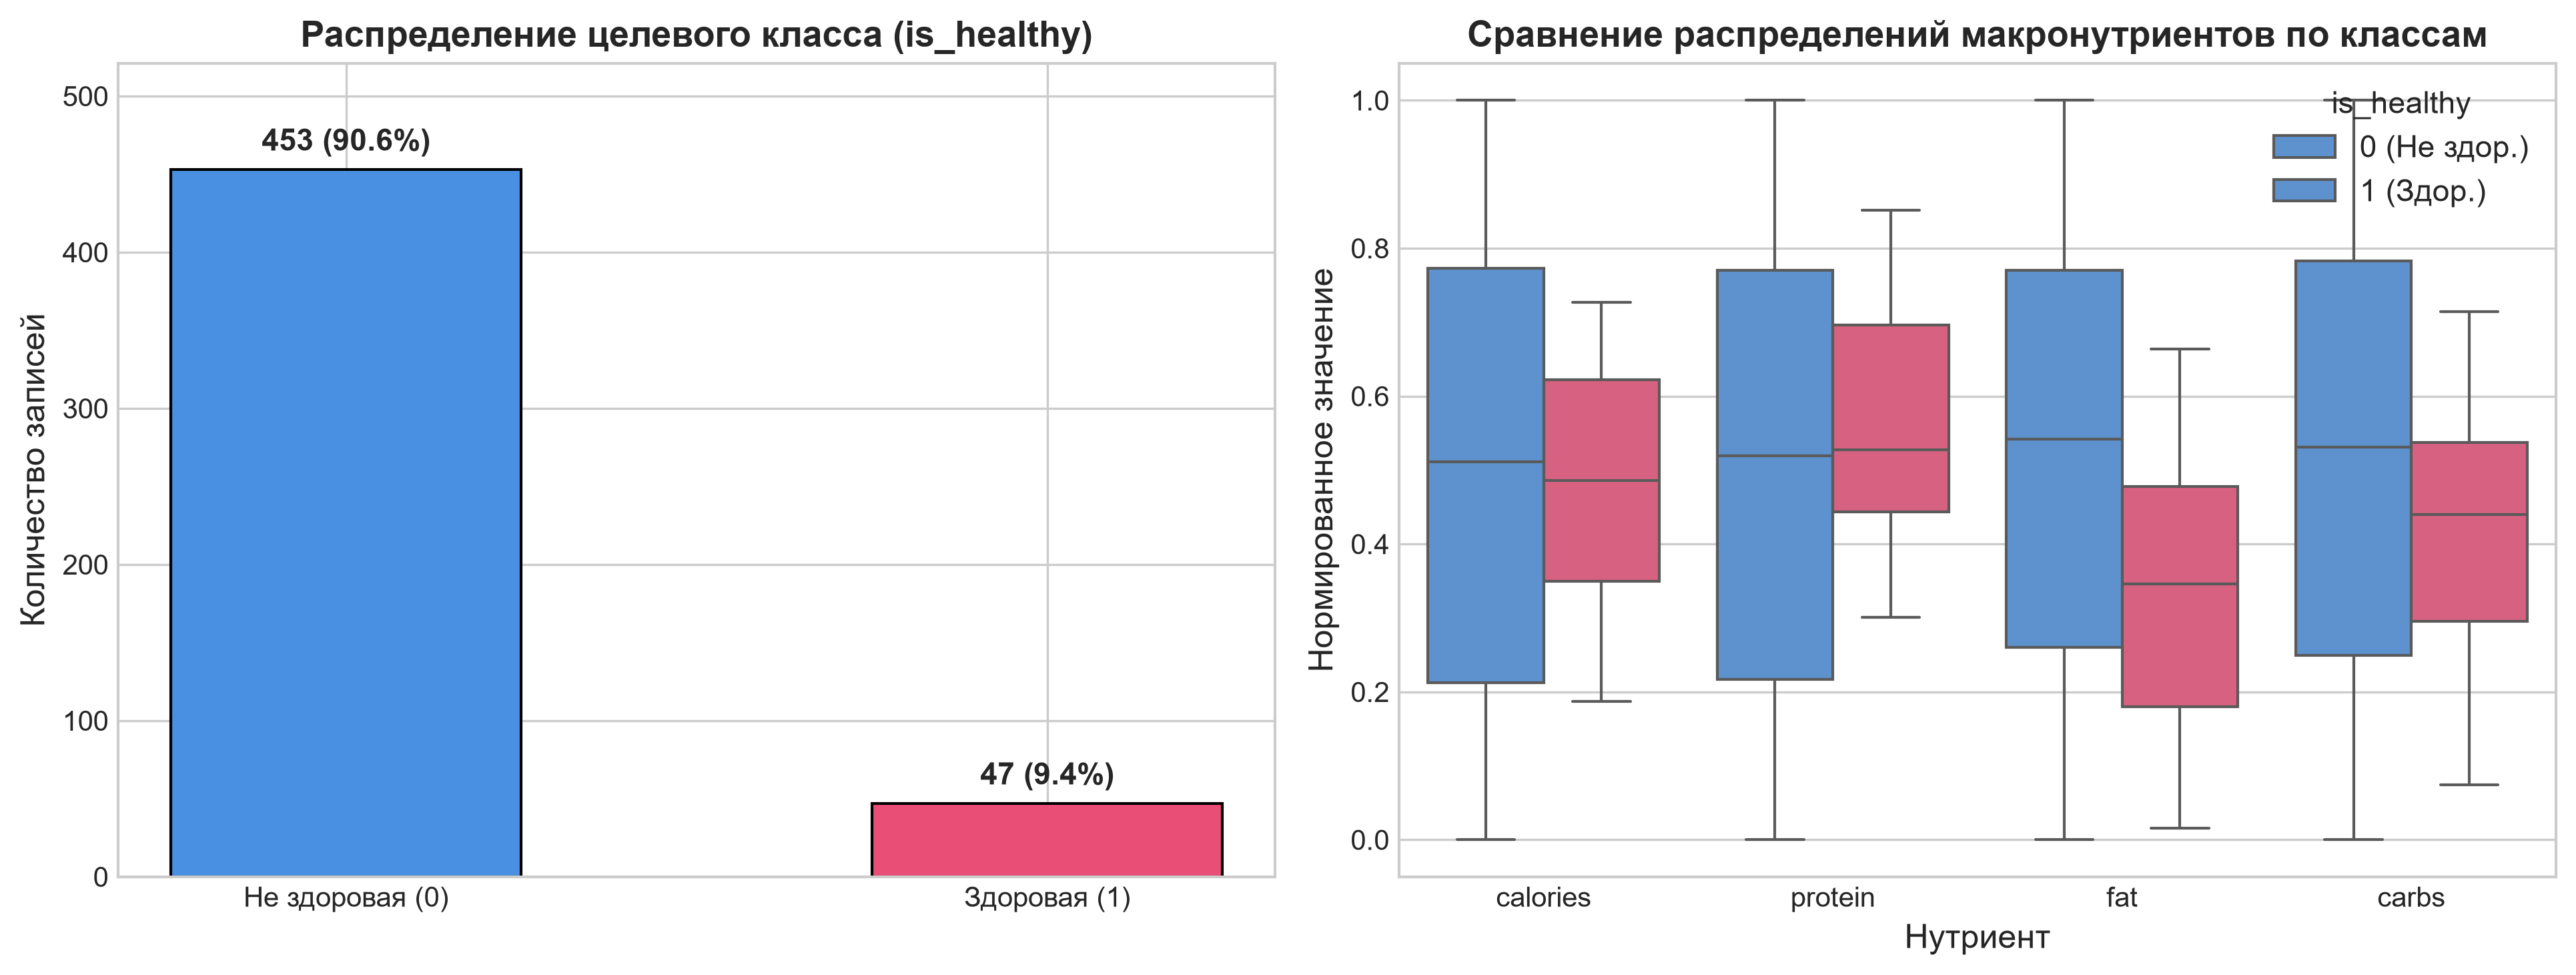

In [4]:
# Визуализация баланса классов и распределения нутриентов
fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=300)

# Баланс классов
colors = ["#4A90E2", "#E94E77"]
bars = axes[0].bar(["Не здоровая (0)", "Здоровая (1)"], target_counts.values, color=colors, width=0.5, edgecolor="black")
axes[0].set_title("Распределение целевого класса (is_healthy)", fontweight="bold")
axes[0].set_ylabel("Количество записей")
axes[0].set_ylim(0, max(target_counts.values) * 1.15)
for bar in bars:
    h = bar.get_height()
    perc = (h / len(raw_df)) * 100
    axes[0].text(bar.get_x() + bar.get_width() / 2, h + 8, f"{int(h)} ({perc:.1f}%)",
                 ha="center", va="bottom", fontweight="bold")

# Боксплоты нутриентов по классам (анализ выбросов и формы распределения)
melted = raw_df.melt(
    id_vars=["is_healthy"],
    value_vars=["calories", "protein", "fat", "carbs"],
    var_name="Нутриент",
    value_name="Нормированное значение"
)
sns.boxplot(
    data=melted,
    x="Нутриент",
    y="Нормированное значение",
    hue="is_healthy",
    palette={0: "#4A90E2", 1: "#E94E77"},
    ax=axes[1]
)
axes[1].set_title("Сравнение распределений макронутриентов по классам", fontweight="bold")
axes[1].legend(title="is_healthy", labels=["0 (Не здор.)", "1 (Здор.)"])

plt.tight_layout()
plt.show()

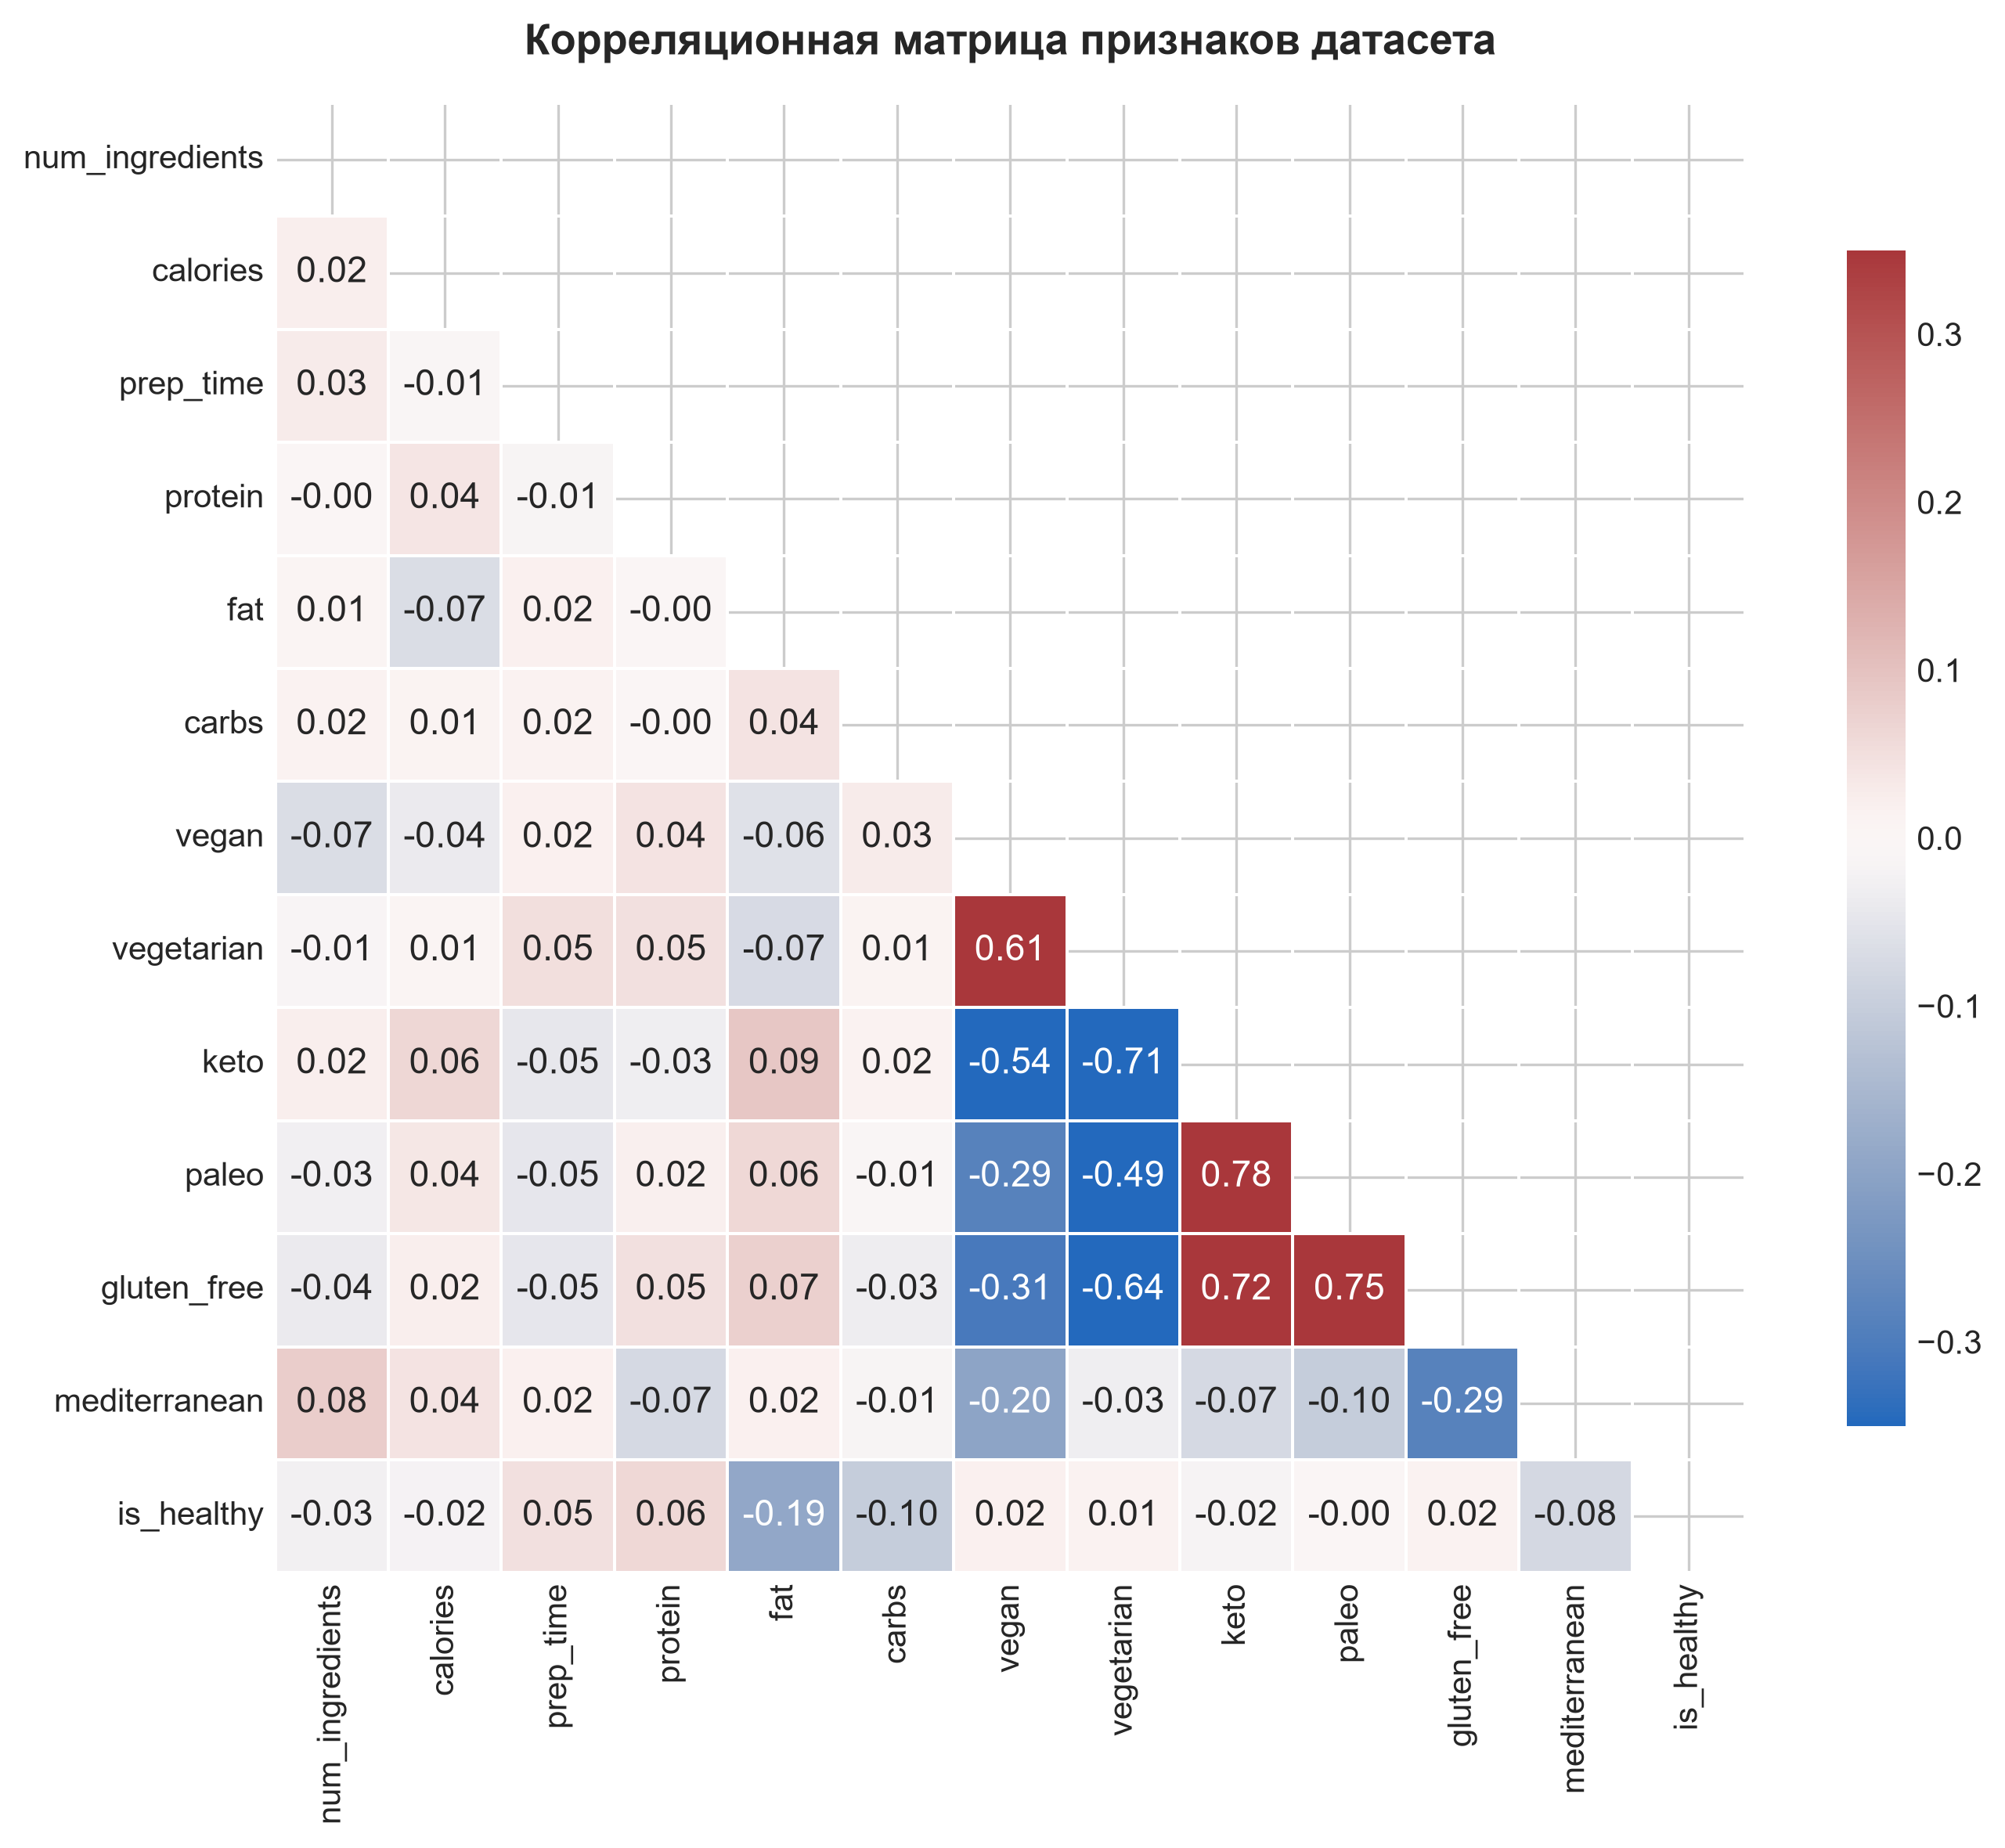

In [5]:
# Построение матрицы корреляций признаков
numerical_cols = [
    "num_ingredients", "calories", "prep_time", "protein", "fat", "carbs",
    "vegan", "vegetarian", "keto", "paleo", "gluten_free", "mediterranean", "is_healthy"
]
corr_matrix = raw_df[numerical_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8), dpi=300)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-0.35,
    vmax=0.35,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    ax=ax
)
ax.set_title("Корреляционная матрица признаков датасета", fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

## 4. Предобработка данных и защита от утечек (Data Leakage)
В строгом соответствии с материалами лекций доц. Лебедевича А. В. («Масштабирование данных»):
1. **Принцип отсутствия утечки:** *«На тесте ничего никогда не считается»*.
2. Разделение на обучающую (Train, 80%) и тестовую (Test, 20%) выборки выполняется строго **до** масштабирования.
3. Поскольку целевой класс сильно несбалансирован (9.4% против 90.6%), разделение выполняется со **стратификацией (`stratify=y`)**, сохраняющей пропорцию классов в обеих выборках.
4. Масштабирование признаков выполняется `StandardScaler`: расчет математического ожидания $\mu$ и дисперсии $\sigma^2$ (`fit`) осуществляется **только** на `X_train`. На тестовой выборке вызывается исключительно `transform`.

In [6]:
# Формирование матриц признаков X и целевого вектора y
feature_cols = [
    "num_ingredients", "calories", "prep_time", "protein", "fat", "carbs",
    "vegan", "vegetarian", "keto", "paleo", "gluten_free", "mediterranean"
]
X = raw_df[feature_cols].copy()
y = raw_df["is_healthy"].values

# Стратифицированное разделение 80/20
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# Стандартизация признаков: fit ТОЛЬКО на train, transform на обоих
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print(f"Размер обучающей выборки X_train: {X_train.shape}, положительных классов: {np.sum(y_train)} ({np.mean(y_train)*100:.1f}%)")
print(f"Размер тестовой выборки X_test:   {X_test.shape}, положительных классов: {np.sum(y_test)} ({np.mean(y_test)*100:.1f}%)")

Размер обучающей выборки X_train: (400, 12), положительных классов: 38 (9.5%)
Размер тестовой выборки X_test:   (100, 12), положительных классов: 9 (9.0%)


## 5. Модель 1: Логистическая регрессия с нуля (Custom Logistic Regression) и эталон Sklearn
Реализуем класс `CustomLogisticRegression` на чистом NumPy:
- Численно стабильная сигмоида $\sigma(z) = \frac{1}{1 + e^{-\text{clip}(z)}}$;
- Функция потерь Log Loss с взвешиванием классов:
  $$\mathcal{L}(w) = -\frac{1}{\sum c_i} \sum_{i=1}^l c_i \left[ y_i \ln(a_i) + (1 - y_i) \ln(1 - a_i) \right] + \frac{\lambda}{2l} \sum_{j=1}^m w_j^2$$
- Векторный градиент $\nabla_w \mathcal{L}(w) = \frac{1}{\sum c_i} X_b^T (c \odot (a - y)) + \frac{\lambda}{l} [0, w_{1:m}]^T$;
- Поддержка весов классов (`class_weight='balanced'`) для компенсации дисбаланса 9:1.

In [7]:
class CustomLogisticRegression:
    """Классификатор логистической регрессии с нуля на NumPy."""
    def __init__(self, learning_rate=0.1, n_iterations=1500, reg_lambda=0.01,
                 class_weight="balanced", fit_intercept=True, tol=1e-6):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.reg_lambda = reg_lambda
        self.class_weight = class_weight
        self.fit_intercept = fit_intercept
        self.tol = tol
        self.weights_ = None
        self.loss_history_ = []

    @staticmethod
    def _sigmoid(z):
        z_clipped = np.clip(z, -500.0, 500.0)
        return 1.0 / (1.0 + np.exp(-z_clipped))

    def _compute_weights(self, y):
        if self.class_weight == "balanced":
            n_samples = len(y)
            n_0 = np.sum(y == 0)
            n_1 = np.sum(y == 1)
            w0 = n_samples / (2.0 * max(n_0, 1))
            w1 = n_samples / (2.0 * max(n_1, 1))
            return np.where(y == 1, w1, w0).astype(float)
        return np.ones(len(y), dtype=float)

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        n_samples, n_features = X.shape

        if self.fit_intercept:
            X_b = np.hstack([np.ones((n_samples, 1), dtype=float), X])
        else:
            X_b = X

        self.weights_ = np.zeros(X_b.shape[1], dtype=float)
        self.loss_history_ = []
        sample_w = self._compute_weights(y)
        w_sum = np.sum(sample_w)

        for _ in range(self.n_iterations):
            z = X_b @ self.weights_
            a = self._sigmoid(z)
            eps = 1e-15
            a_safe = np.clip(a, eps, 1.0 - eps)

            # Log loss с весами
            unreg_loss = - (1.0 / w_sum) * np.sum(sample_w * (y * np.log(a_safe) + (1.0 - y) * np.log(1.0 - a_safe)))
            reg_penalty = (self.reg_lambda / (2.0 * n_samples)) * np.sum(self.weights_[1:] ** 2) if self.fit_intercept else 0.0
            self.loss_history_.append(unreg_loss + reg_penalty)

            # Градиент
            grad = (1.0 / w_sum) * (X_b.T @ (sample_w * (a - y)))
            if self.reg_lambda > 0 and self.fit_intercept:
                reg_grad = (self.reg_lambda / n_samples) * self.weights_.copy()
                reg_grad[0] = 0.0
                grad += reg_grad

            if np.linalg.norm(grad) < self.tol:
                break
            self.weights_ -= self.learning_rate * grad

        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        if self.fit_intercept:
            X_b = np.hstack([np.ones((X.shape[0], 1), dtype=float), X])
        else:
            X_b = X
        p1 = self._sigmoid(X_b @ self.weights_)
        return np.column_stack([1.0 - p1, p1])

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

    def score(self, X, y):
        return np.mean(self.predict(X) == np.asarray(y).ravel())

In [8]:
# Обучение Custom Logistic Regression и эталона Sklearn LogisticRegression
custom_logreg = CustomLogisticRegression(learning_rate=0.1, n_iterations=1500, reg_lambda=0.01, class_weight="balanced")
custom_logreg.fit(X_train, y_train)

sklearn_logreg = LogisticRegression(class_weight="balanced", random_state=RANDOM_STATE)
sklearn_logreg.fit(X_train, y_train)

# Оценка предсказаний
y_pred_custom_lr = custom_logreg.predict(X_test)
y_prob_custom_lr = custom_logreg.predict_proba(X_test)[:, 1]

y_pred_sk_lr = sklearn_logreg.predict(X_test)
y_prob_sk_lr = sklearn_logreg.predict_proba(X_test)[:, 1]

print("=== СРАВНЕНИЕ РЕЗУЛЬТАТОВ ЛОГИСТИЧЕСКОЙ РЕГРЕССИИ ===")
print(f"Custom LogReg:  Accuracy = {accuracy_score(y_test, y_pred_custom_lr):.4f}, F1 = {f1_score(y_test, y_pred_custom_lr):.4f}, ROC-AUC = {roc_auc_score(y_test, y_prob_custom_lr):.4f}")
print(f"Sklearn LogReg: Accuracy = {accuracy_score(y_test, y_pred_sk_lr):.4f}, F1 = {f1_score(y_test, y_pred_sk_lr):.4f}, ROC-AUC = {roc_auc_score(y_test, y_prob_sk_lr):.4f}")

=== СРАВНЕНИЕ РЕЗУЛЬТАТОВ ЛОГИСТИЧЕСКОЙ РЕГРЕССИИ ===
Custom LogReg:  Accuracy = 0.6300, F1 = 0.2128, ROC-AUC = 0.6264
Sklearn LogReg: Accuracy = 0.6300, F1 = 0.2128, ROC-AUC = 0.6276


## 6. Модель 2: Метод опорных векторов (SVM) с нуля и ядерный SVM Scikit-Learn
Реализуем линейный метод опорных векторов `CustomLinearSVM`:
- Функция потерь Hinge Loss с $L_2$-штрафом: $\min_{w, b} \frac{1}{2}\|w\|^2 + C \sum \max(0, 1 - y_i(w^T x_i + b))$;
- Оптимизация методом субградиентного спуска (алгоритм Pegasos);
- Определение опорных векторов (объектов с отступом $M_i \le 1.05$).
Также исследуем ядерный классификатор `SVC` (Scikit-Learn) с радиальной базисной функцией (RBF ядро), позволяющий разделять данные нелинейной конфигурации.

In [9]:
class CustomLinearSVM:
    """Линейный SVM субградиентным спуском (Pegasos) с нуля на NumPy."""
    def __init__(self, C=1.0, learning_rate=0.005, n_iterations=1500, class_weight="balanced"):
        self.C = C
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.class_weight = class_weight
        self.w_ = None
        self.b_ = 0.0
        self.loss_history_ = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y_signed = np.where(np.asarray(y).ravel() == 0, -1.0, 1.0)
        n_samples, n_features = X.shape

        self.w_ = np.zeros(n_features, dtype=float)
        self.b_ = 0.0
        self.loss_history_ = []

        # Веса классов
        w_pos = n_samples / (2.0 * max(np.sum(y == 1), 1)) if self.class_weight == "balanced" else 1.0
        w_neg = n_samples / (2.0 * max(np.sum(y == 0), 1)) if self.class_weight == "balanced" else 1.0
        weights = np.where(y_signed == 1, w_pos, w_neg)

        for epoch in range(1, self.n_iterations + 1):
            lr = self.learning_rate / (1.0 + 0.001 * epoch)
            margins = y_signed * (X @ self.w_ + self.b_)
            hinge = np.maximum(0.0, 1.0 - margins)
            loss = 0.5 * np.sum(self.w_ ** 2) + self.C * np.mean(weights * hinge)
            self.loss_history_.append(loss)

            violators = (margins < 1.0).astype(float) * weights
            grad_w = self.w_ - (self.C / n_samples) * (X.T @ (violators * y_signed))
            grad_b = - (self.C / n_samples) * np.sum(violators * y_signed)

            self.w_ -= lr * grad_w
            self.b_ -= lr * grad_b

        return self

    def decision_function(self, X):
        return np.asarray(X, dtype=float) @ self.w_ + self.b_

    def predict(self, X):
        return (self.decision_function(X) >= 0.0).astype(int)

In [10]:
# Обучение Custom Linear SVM, Sklearn Linear SVM и Sklearn RBF SVM
custom_svm = CustomLinearSVM(C=1.0, learning_rate=0.005, n_iterations=1500, class_weight="balanced")
custom_svm.fit(X_train, y_train)

sklearn_svm_lin = SVC(kernel="linear", C=1.0, class_weight="balanced", probability=True, random_state=RANDOM_STATE)
sklearn_svm_lin.fit(X_train, y_train)

sklearn_svm_rbf = SVC(kernel="rbf", C=5.0, class_weight="balanced", probability=True, random_state=RANDOM_STATE)
sklearn_svm_rbf.fit(X_train, y_train)

y_pred_c_svm = custom_svm.predict(X_test)
y_pred_sk_lin = sklearn_svm_lin.predict(X_test)
y_pred_sk_rbf = sklearn_svm_rbf.predict(X_test)
y_prob_sk_rbf = sklearn_svm_rbf.predict_proba(X_test)[:, 1]

print("=== СРАВНЕНИЕ МОДЕЛЕЙ МЕТОДА ОПОРНЫХ ВЕКТОРОВ (SVM) ===")
print(f"Custom Linear SVM: Accuracy = {accuracy_score(y_test, y_pred_c_svm):.4f}, F1 = {f1_score(y_test, y_pred_c_svm):.4f}")
print(f"Sklearn Linear SVM: Accuracy = {accuracy_score(y_test, y_pred_sk_lin):.4f}, F1 = {f1_score(y_test, y_pred_sk_lin):.4f}")
print(f"Sklearn RBF SVM:    Accuracy = {accuracy_score(y_test, y_pred_sk_rbf):.4f}, F1 = {f1_score(y_test, y_pred_sk_rbf):.4f}, ROC-AUC = {roc_auc_score(y_test, y_prob_sk_rbf):.4f}")

=== СРАВНЕНИЕ МОДЕЛЕЙ МЕТОДА ОПОРНЫХ ВЕКТОРОВ (SVM) ===
Custom Linear SVM: Accuracy = 0.5700, F1 = 0.2456
Sklearn Linear SVM: Accuracy = 0.6300, F1 = 0.2449
Sklearn RBF SVM:    Accuracy = 0.9100, F1 = 0.5714, ROC-AUC = 0.9096


## 7. Модель 3: Деревья принятия решений (CART) с нуля и эталон Sklearn
Реализуем классификатор `CustomDecisionTree` с поддержкой:
- Индекса неопределенности Джини $G = 1 - (p_0^2 + p_1^2)$ и энтропии Шеннона $H = -\sum p_k \log_2(p_k)$;
- Поиска наилучшего бинарного разбиения по критерию максимума Information Gain;
- Ограничения глубины дерева `max_depth` и минимального размера узла `min_samples_split`;
- Взвешивания классов `class_weight='balanced'`;
- Сопоставления с эталонной реализацией `DecisionTreeClassifier` из библиотеки Scikit-Learn.

In [11]:
class TreeNode:
    def __init__(self, feature_idx=None, threshold=None, left=None, right=None,
                 value=None, probabilities=None):
        self.feature_idx = feature_idx
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value
        self.probabilities = probabilities

    @property
    def is_leaf(self):
        return self.value is not None


class CustomDecisionTree:
    """Дерево решений CART с нуля на NumPy."""
    def __init__(self, criterion="gini", max_depth=4, min_samples_split=5, class_weight="balanced"):
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.class_weight = class_weight
        self.root_ = None

    def _impurity(self, y, weights):
        if len(y) == 0:
            return 0.0
        w_tot = np.sum(weights)
        p1 = np.sum(weights[y == 1]) / w_tot if w_tot > 0 else 0.0
        p0 = 1.0 - p1
        if self.criterion == "gini":
            return 1.0 - (p0**2 + p1**2)
        eps = 1e-15
        h0 = -p0 * np.log2(p0 + eps) if p0 > 0 else 0.0
        h1 = -p1 * np.log2(p1 + eps) if p1 > 0 else 0.0
        return h0 + h1

    def _best_split(self, X, y, weights):
        n_samples, n_features = X.shape
        parent_imp = self._impurity(y, weights)
        parent_w = np.sum(weights)
        best_gain, best_feat, best_thresh = -1.0, None, None

        for feat in range(n_features):
            vals = np.unique(X[:, feat])
            if len(vals) <= 1:
                continue
            thresholds = (vals[:-1] + vals[1:]) / 2.0
            for t in thresholds:
                left = X[:, feat] <= t
                right = ~left
                if np.sum(left) < 2 or np.sum(right) < 2:
                    continue
                w_l, w_r = np.sum(weights[left]), np.sum(weights[right])
                imp_l = self._impurity(y[left], weights[left])
                imp_r = self._impurity(y[right], weights[right])
                gain = parent_imp - (w_l / parent_w) * imp_l - (w_r / parent_w) * imp_r
                if gain > best_gain:
                    best_gain, best_feat, best_thresh = gain, feat, t

        return best_feat, best_thresh, best_gain

    def _build(self, X, y, weights, depth=0):
        w_tot = np.sum(weights)
        p1 = np.sum(weights[y == 1]) / w_tot if w_tot > 0 else 0.0
        maj_cls = 1 if p1 >= 0.5 else 0

        if depth >= self.max_depth or len(y) < self.min_samples_split or np.all(y == y[0]):
            return TreeNode(value=maj_cls, probabilities=np.array([1.0 - p1, p1]))

        feat, thresh, gain = self._best_split(X, y, weights)
        if feat is None or gain <= 1e-7:
            return TreeNode(value=maj_cls, probabilities=np.array([1.0 - p1, p1]))

        left_mask = X[:, feat] <= thresh
        return TreeNode(
            feature_idx=feat,
            threshold=thresh,
            left=self._build(X[left_mask], y[left_mask], weights[left_mask], depth + 1),
            right=self._build(X[~left_mask], y[~left_mask], weights[~left_mask], depth + 1)
        )

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int).ravel()
        n = len(y)
        if self.class_weight == "balanced":
            w0 = n / (2.0 * max(np.sum(y == 0), 1))
            w1 = n / (2.0 * max(np.sum(y == 1), 1))
            weights = np.where(y == 1, w1, w0).astype(float)
        else:
            weights = np.ones(n, dtype=float)
        self.root_ = self._build(X, y, weights, depth=0)
        return self

    def _predict_one(self, x, node):
        if node.is_leaf:
            return node.value
        return self._predict_one(x, node.left) if x[node.feature_idx] <= node.threshold else self._predict_one(x, node.right)

    def _predict_proba_one(self, x, node):
        if node.is_leaf:
            return node.probabilities
        return self._predict_proba_one(x, node.left) if x[node.feature_idx] <= node.threshold else self._predict_proba_one(x, node.right)

    def predict(self, X):
        return np.array([self._predict_one(x, self.root_) for x in np.asarray(X, dtype=float)])

    def predict_proba(self, X):
        return np.array([self._predict_proba_one(x, self.root_) for x in np.asarray(X, dtype=float)])

In [12]:
# Обучение Custom Decision Tree и эталона Sklearn DecisionTreeClassifier
custom_cart_gini = CustomDecisionTree(criterion="gini", max_depth=4, min_samples_split=5, class_weight="balanced")
custom_cart_gini.fit(X_train, y_train)

sklearn_cart = DecisionTreeClassifier(criterion="gini", max_depth=4, min_samples_split=5, class_weight="balanced", random_state=RANDOM_STATE)
sklearn_cart.fit(X_train, y_train)

y_pred_c_tree = custom_cart_gini.predict(X_test)
y_prob_c_tree = custom_cart_gini.predict_proba(X_test)[:, 1]

y_pred_sk_tree = sklearn_cart.predict(X_test)
y_prob_sk_tree = sklearn_cart.predict_proba(X_test)[:, 1]

print("=== СРАВНЕНИЕ ДЕРЕВЬЕВ РЕШЕНИЙ (CART) ===")
print(f"Custom CART:  Accuracy = {accuracy_score(y_test, y_pred_c_tree):.4f}, Recall = {recall_score(y_test, y_pred_c_tree):.4f}, F1 = {f1_score(y_test, y_pred_c_tree):.4f}, ROC-AUC = {roc_auc_score(y_test, y_prob_c_tree):.4f}")
print(f"Sklearn CART: Accuracy = {accuracy_score(y_test, y_pred_sk_tree):.4f}, Recall = {recall_score(y_test, y_pred_sk_tree):.4f}, F1 = {f1_score(y_test, y_pred_sk_tree):.4f}, ROC-AUC = {roc_auc_score(y_test, y_prob_sk_tree):.4f}")

=== СРАВНЕНИЕ ДЕРЕВЬЕВ РЕШЕНИЙ (CART) ===
Custom CART:  Accuracy = 0.8100, Recall = 0.8889, F1 = 0.4571, ROC-AUC = 0.8455
Sklearn CART: Accuracy = 0.8100, Recall = 0.8889, F1 = 0.4571, ROC-AUC = 0.8455


## 8. Исследование регуляризации и переобучения дерева решений (max_depth)
Деревья решений подвержены катастрофическому переобучению при неограниченной глубине: дерево запоминает шум обучающей выборки, достигая 100% точности на Train, но теряет обобщающую способность на Test.
Проведем параметрический эксперимент по варьированию `max_depth` от 1 до 15 и построим кривые переобучения.

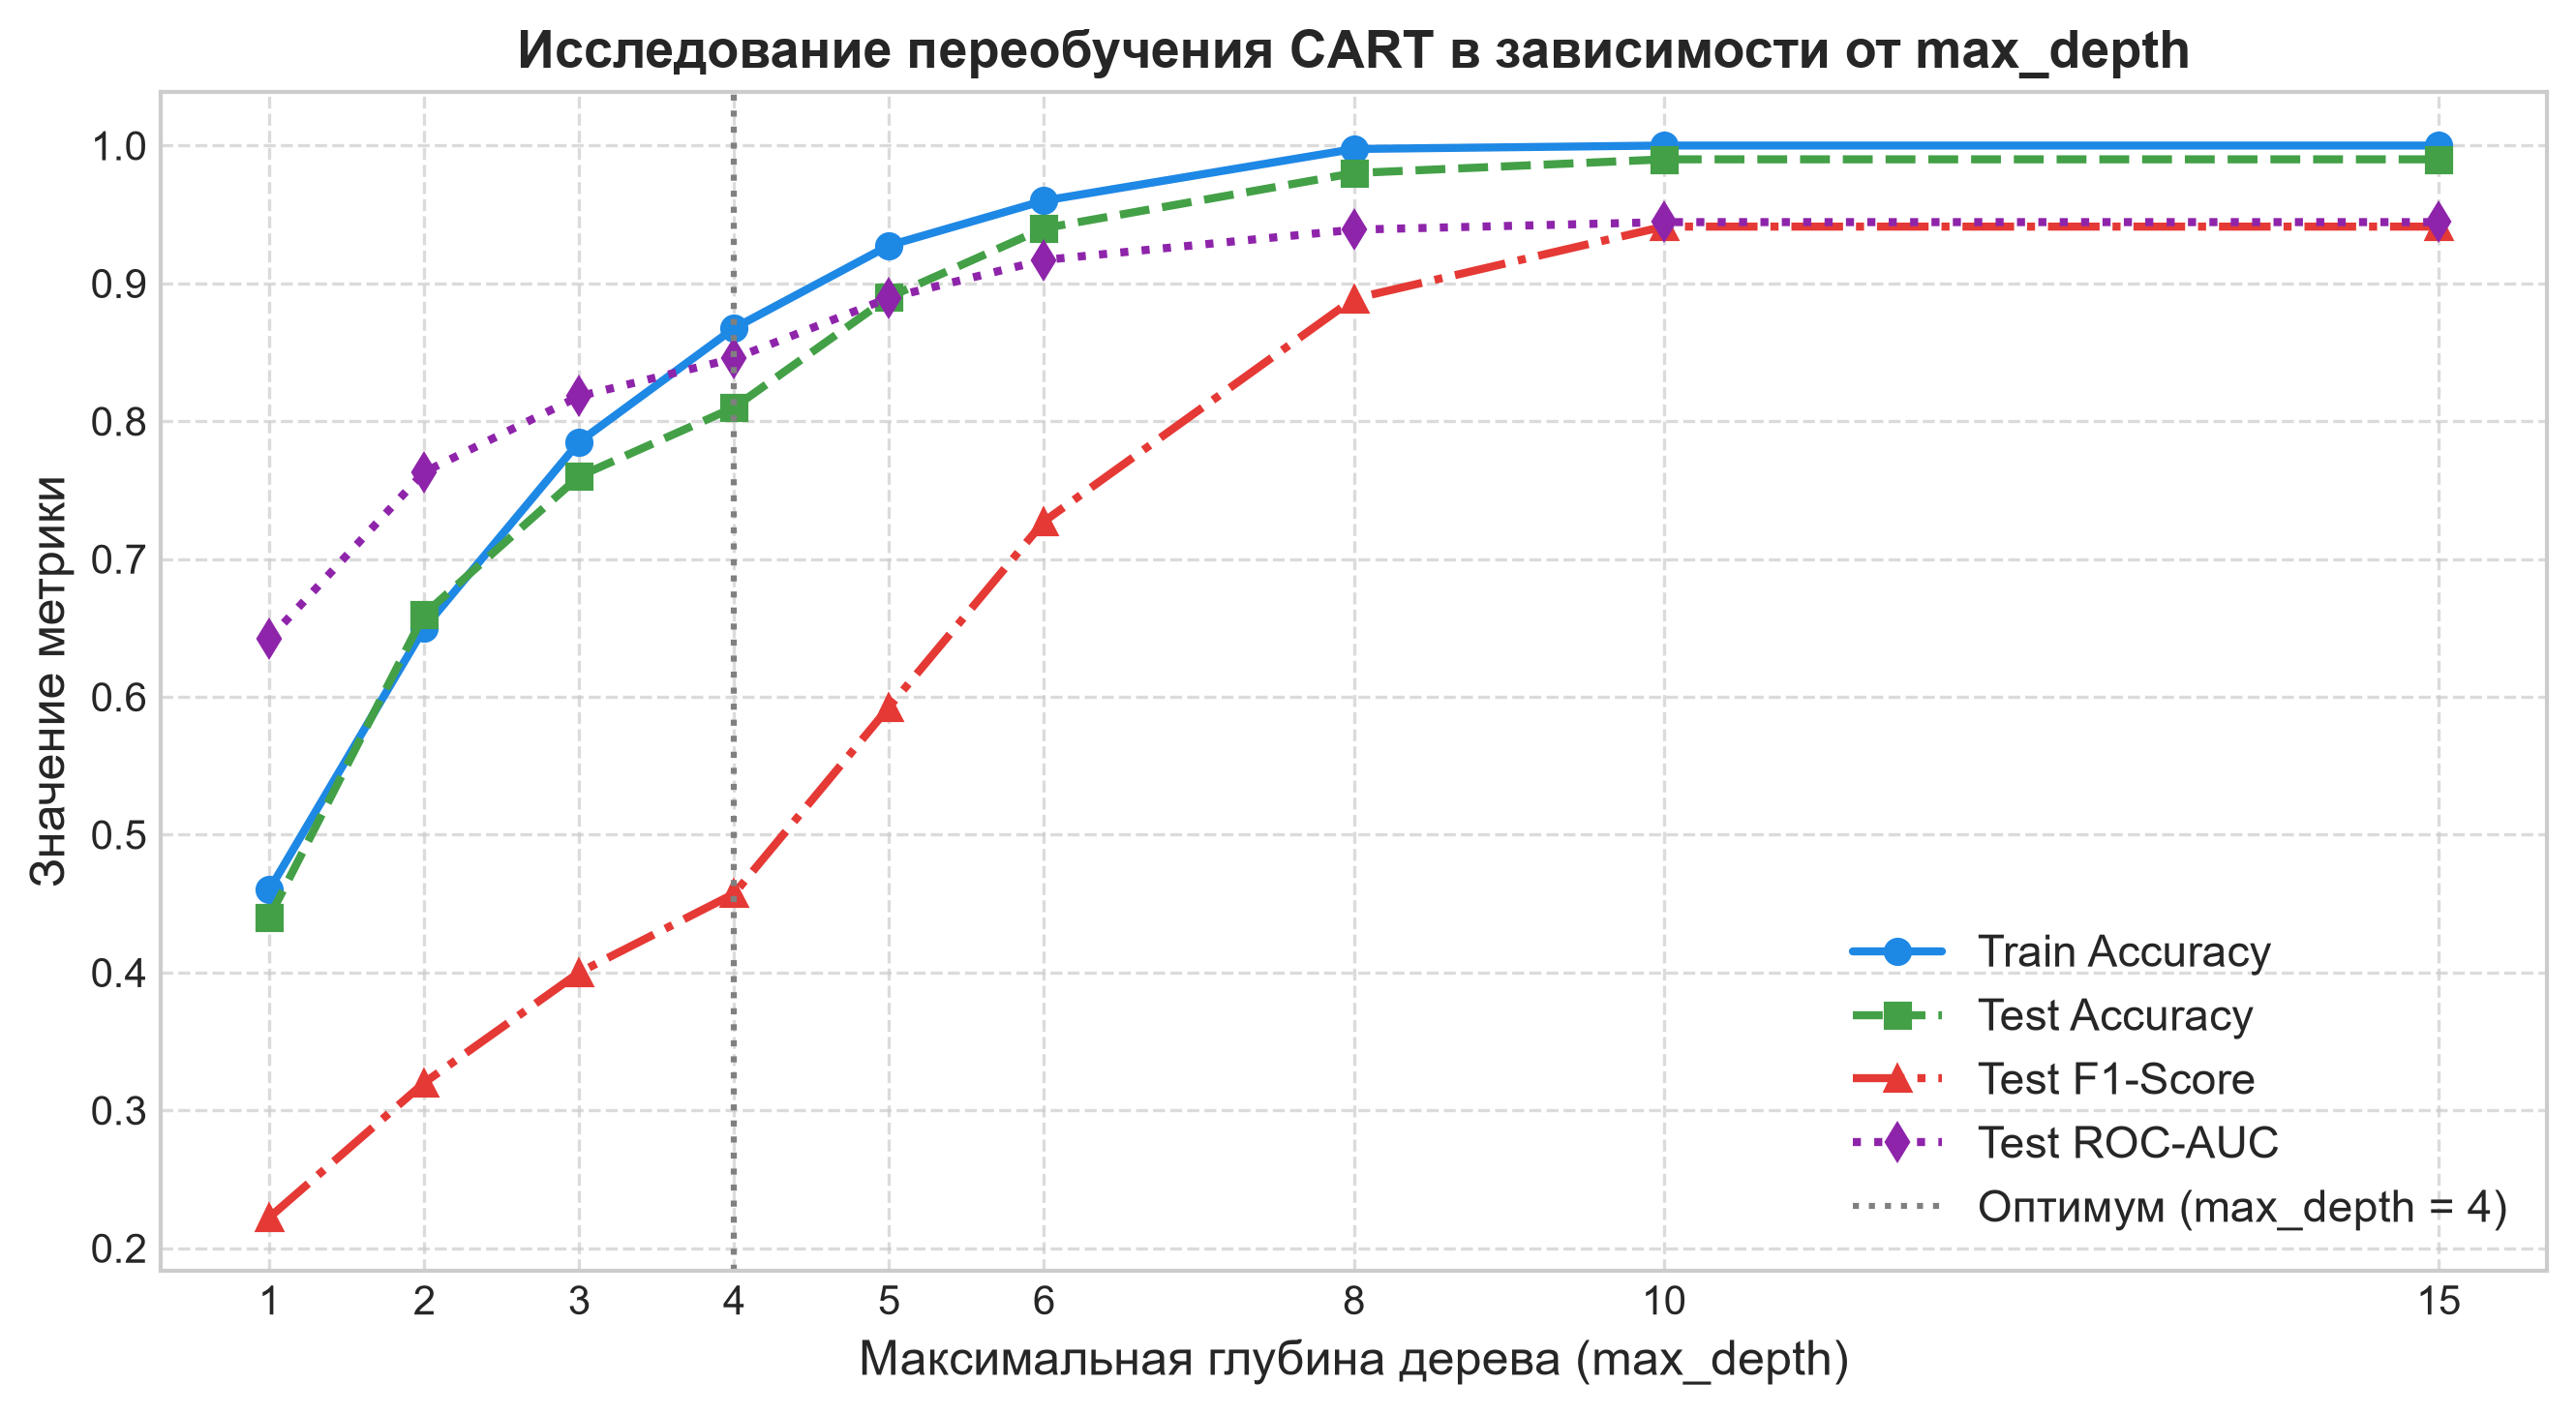

Сводные результаты по глубине дерева:


,Depth,Train_Accuracy,Test_Accuracy,Test_F1,Test_ROC_AUC
0,1,0.4600,0.44,0.222222,0.642247
1,2,0.6500,0.66,0.320000,0.763126
2,3,0.7850,0.76,0.400000,0.818071
3,4,0.8675,0.81,0.457143,0.845543
4,5,0.9275,0.89,0.592593,0.889499
5,6,0.9600,0.94,0.727273,0.916972
6,8,0.9975,0.98,0.888889,0.938950
7,10,1.0000,0.99,0.941176,0.944444
8,15,1.0000,0.99,0.941176,0.944444


In [13]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 15]
depth_records = []

for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, class_weight="balanced", random_state=RANDOM_STATE)
    clf.fit(X_train, y_train)
    tr_acc = clf.score(X_train, y_train)
    te_acc = clf.score(X_test, y_test)
    te_f1 = f1_score(y_test, clf.predict(X_test), zero_division=0)
    te_roc = roc_auc_score(y_test, clf.predict_proba(X_test)[:, 1])
    depth_records.append({
        "Depth": d,
        "Train_Accuracy": tr_acc,
        "Test_Accuracy": te_acc,
        "Test_F1": te_f1,
        "Test_ROC_AUC": te_roc
    })

depth_df = pd.DataFrame(depth_records)

fig, ax = plt.subplots(figsize=(9, 5), dpi=300)
ax.plot(depth_df["Depth"], depth_df["Train_Accuracy"], "o-", color="#1E88E5", lw=2, label="Train Accuracy")
ax.plot(depth_df["Depth"], depth_df["Test_Accuracy"], "s--", color="#43A047", lw=2, label="Test Accuracy")
ax.plot(depth_df["Depth"], depth_df["Test_F1"], "^-.", color="#E53935", lw=2, label="Test F1-Score")
ax.plot(depth_df["Depth"], depth_df["Test_ROC_AUC"], "d:", color="#8E24AA", lw=2, label="Test ROC-AUC")
ax.set_title("Исследование переобучения CART в зависимости от max_depth", fontweight="bold")
ax.set_xlabel("Максимальная глубина дерева (max_depth)")
ax.set_ylabel("Значение метрики")
ax.set_xticks(depths)
ax.axvline(x=4, color="gray", linestyle=":", lw=1.5, label="Оптимум (max_depth = 4)")
ax.legend(loc="lower right")
ax.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

print("Сводные результаты по глубине дерева:")
depth_df

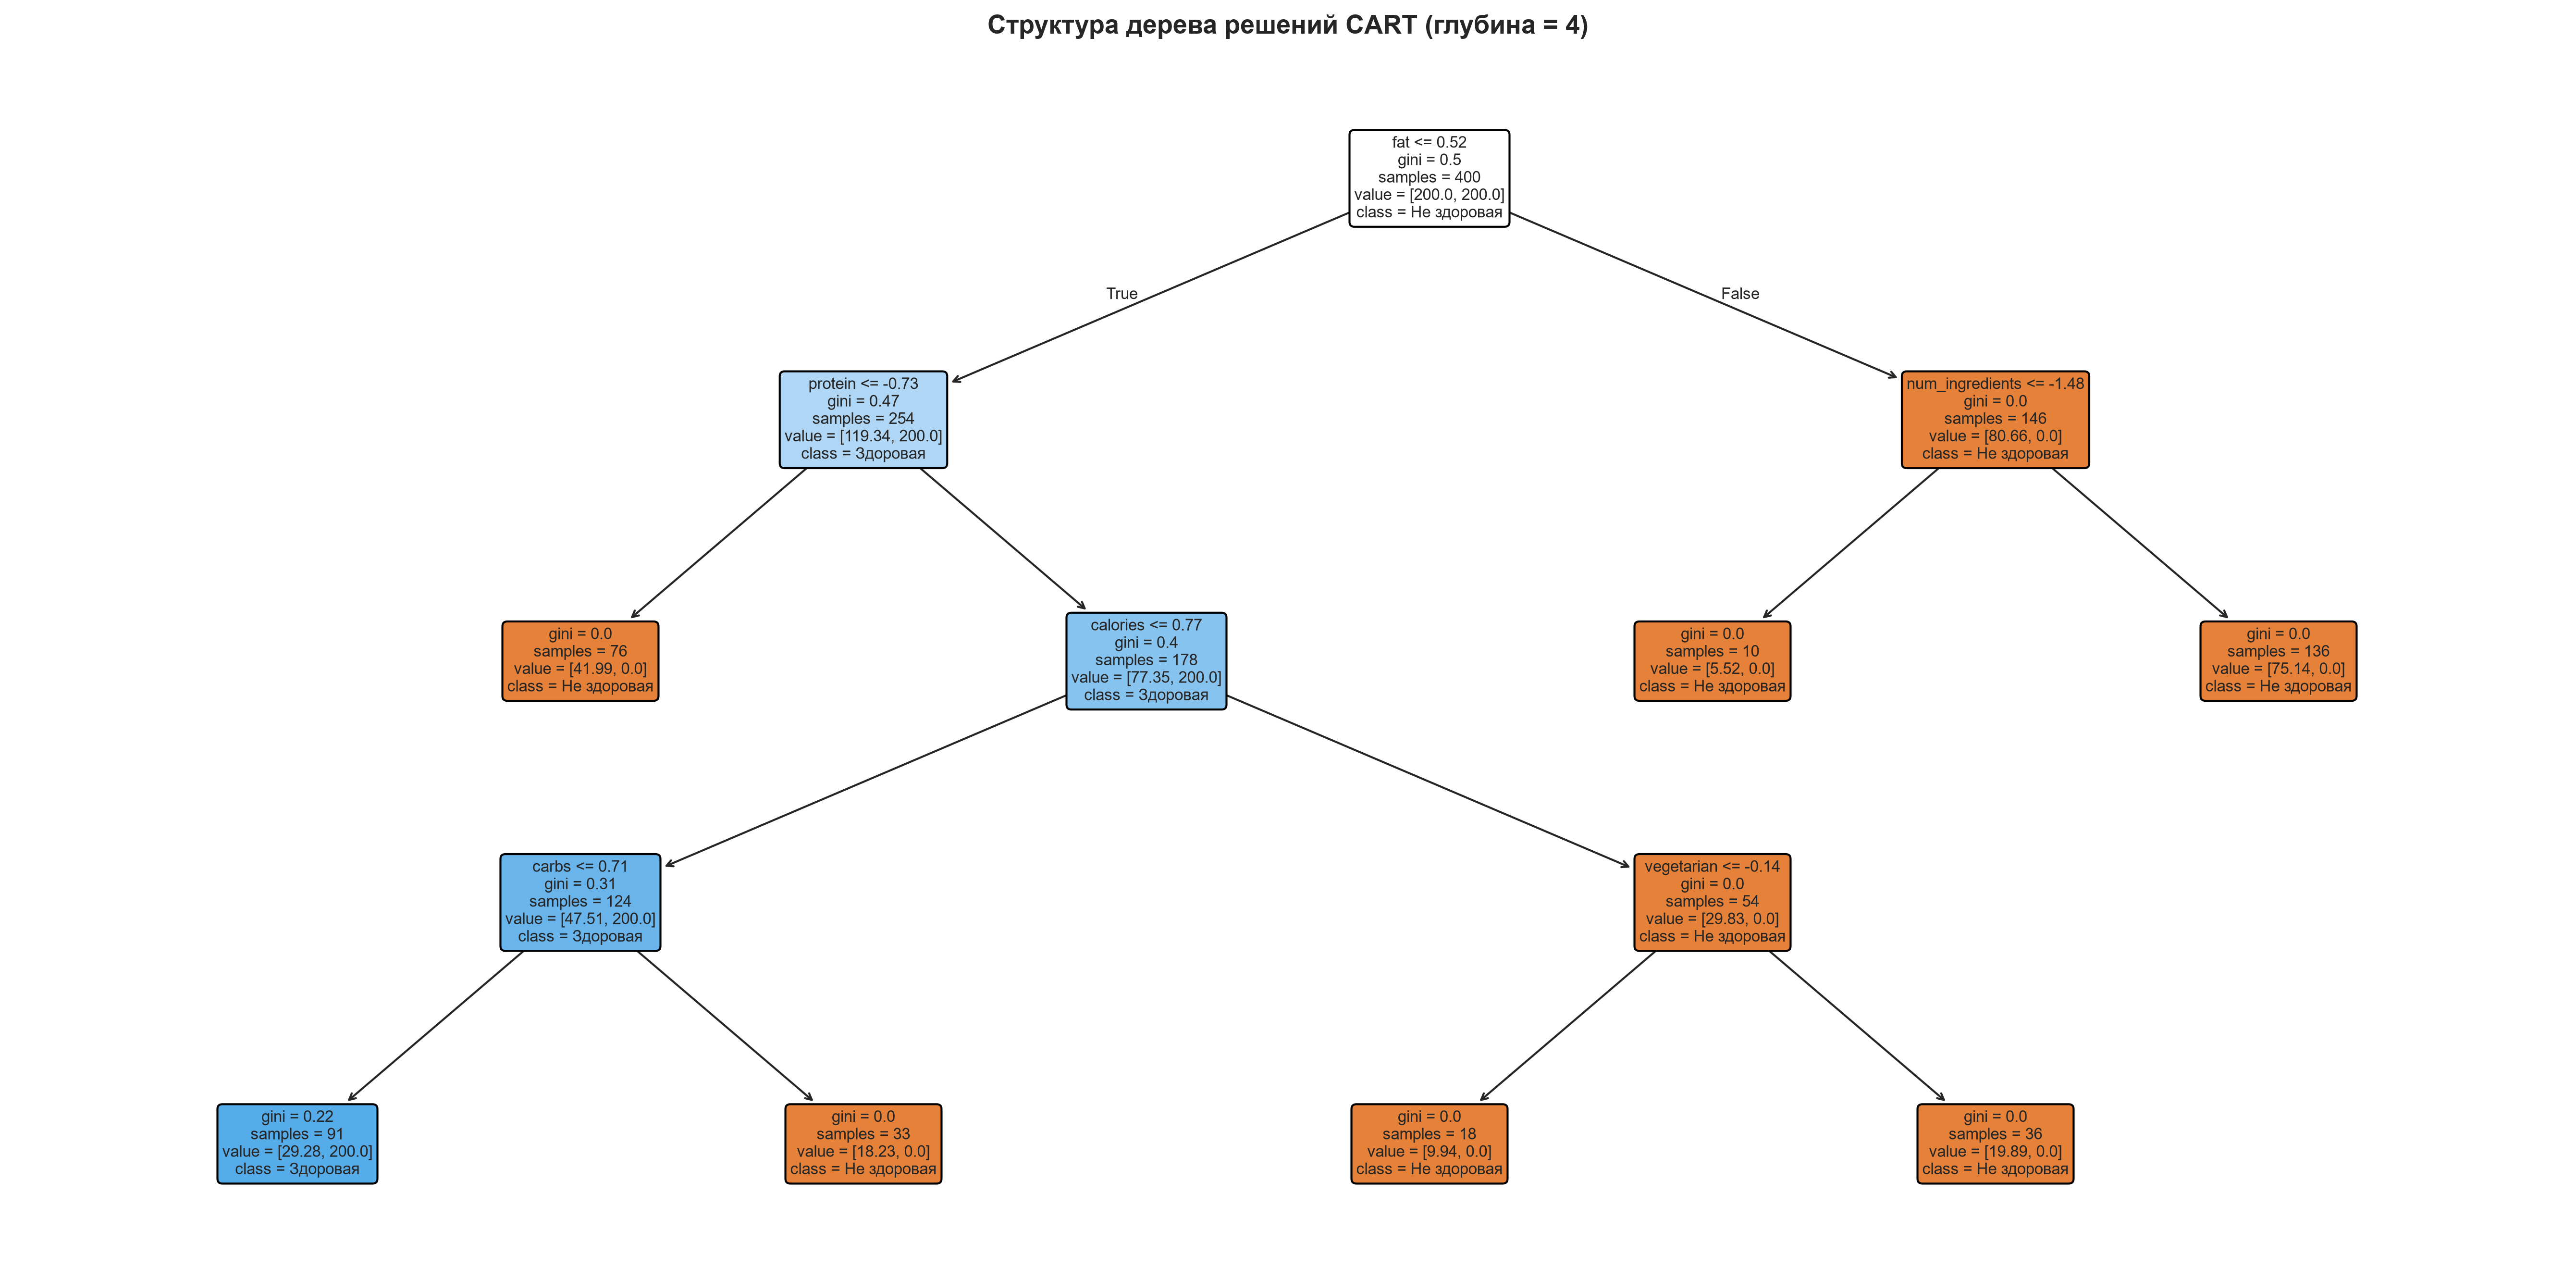

In [14]:
# Графическая визуализация структуры дерева решений
fig, ax = plt.subplots(figsize=(18, 9), dpi=300)
plot_tree(
    sklearn_cart,
    feature_names=feature_cols,
    class_names=["Не здоровая", "Здоровая"],
    filled=True,
    rounded=True,
    fontsize=8,
    precision=2,
    ax=ax
)
ax.set_title("Структура дерева решений CART (глубина = 4)", fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

## 9. Сравнительный бенчмарк моделей, матрицы ошибок и анализ кривых ROC-AUC / PR-AUC
Построим комплексный бенчмарк всех разработанных моделей и визуализируем:
1. Матрицы ошибок (Confusion Matrices) с абсолютными числами и долями в ячейках;
2. Кривые ROC-AUC (сравнение способности отсечения при различных порогах);
3. Кривые Precision-Recall (PR-AUC) против априорного базового уровня редкого класса;
4. Итоговую сводную таблицу качества.

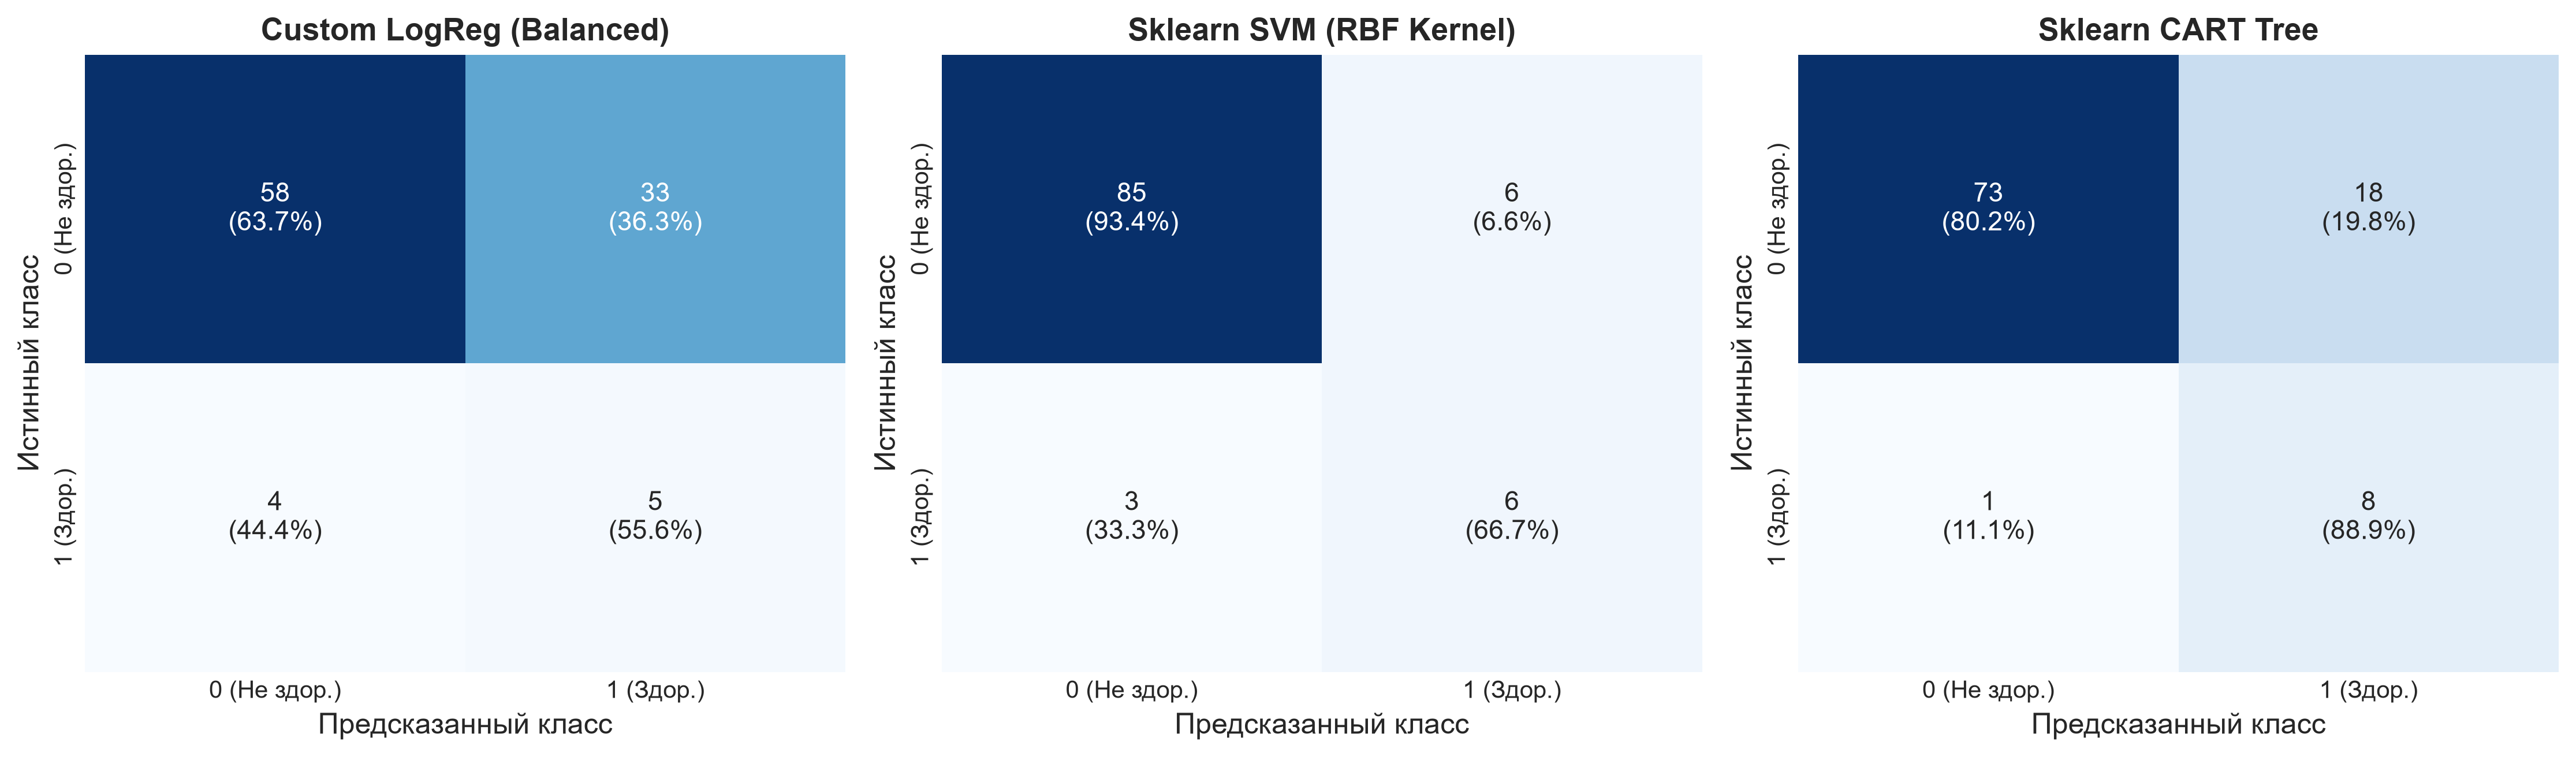

In [15]:
# Визуализация матриц ошибок для 3 ключевых алгоритмов
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=300)
models_for_cm = {
    "Custom LogReg (Balanced)": y_pred_custom_lr,
    "Sklearn SVM (RBF Kernel)": y_pred_sk_rbf,
    "Sklearn CART Tree": y_pred_sk_tree
}

for idx, (title, pred) in enumerate(models_for_cm.items()):
    cm = confusion_matrix(y_test, pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis]
    annot = np.empty_like(cm, dtype=object)
    for r in range(cm.shape[0]):
        for c in range(cm.shape[1]):
            annot[r, c] = f"{cm[r, c]}\n({cm_norm[r, c]*100:.1f}%)"
    sns.heatmap(
        cm, annot=annot, fmt="", cmap="Blues", cbar=False, ax=axes[idx],
        xticklabels=["0 (Не здор.)", "1 (Здор.)"], yticklabels=["0 (Не здор.)", "1 (Здор.)"]
    )
    axes[idx].set_title(title, fontweight="bold")
    axes[idx].set_xlabel("Предсказанный класс")
    axes[idx].set_ylabel("Истинный класс")

plt.tight_layout()
plt.show()

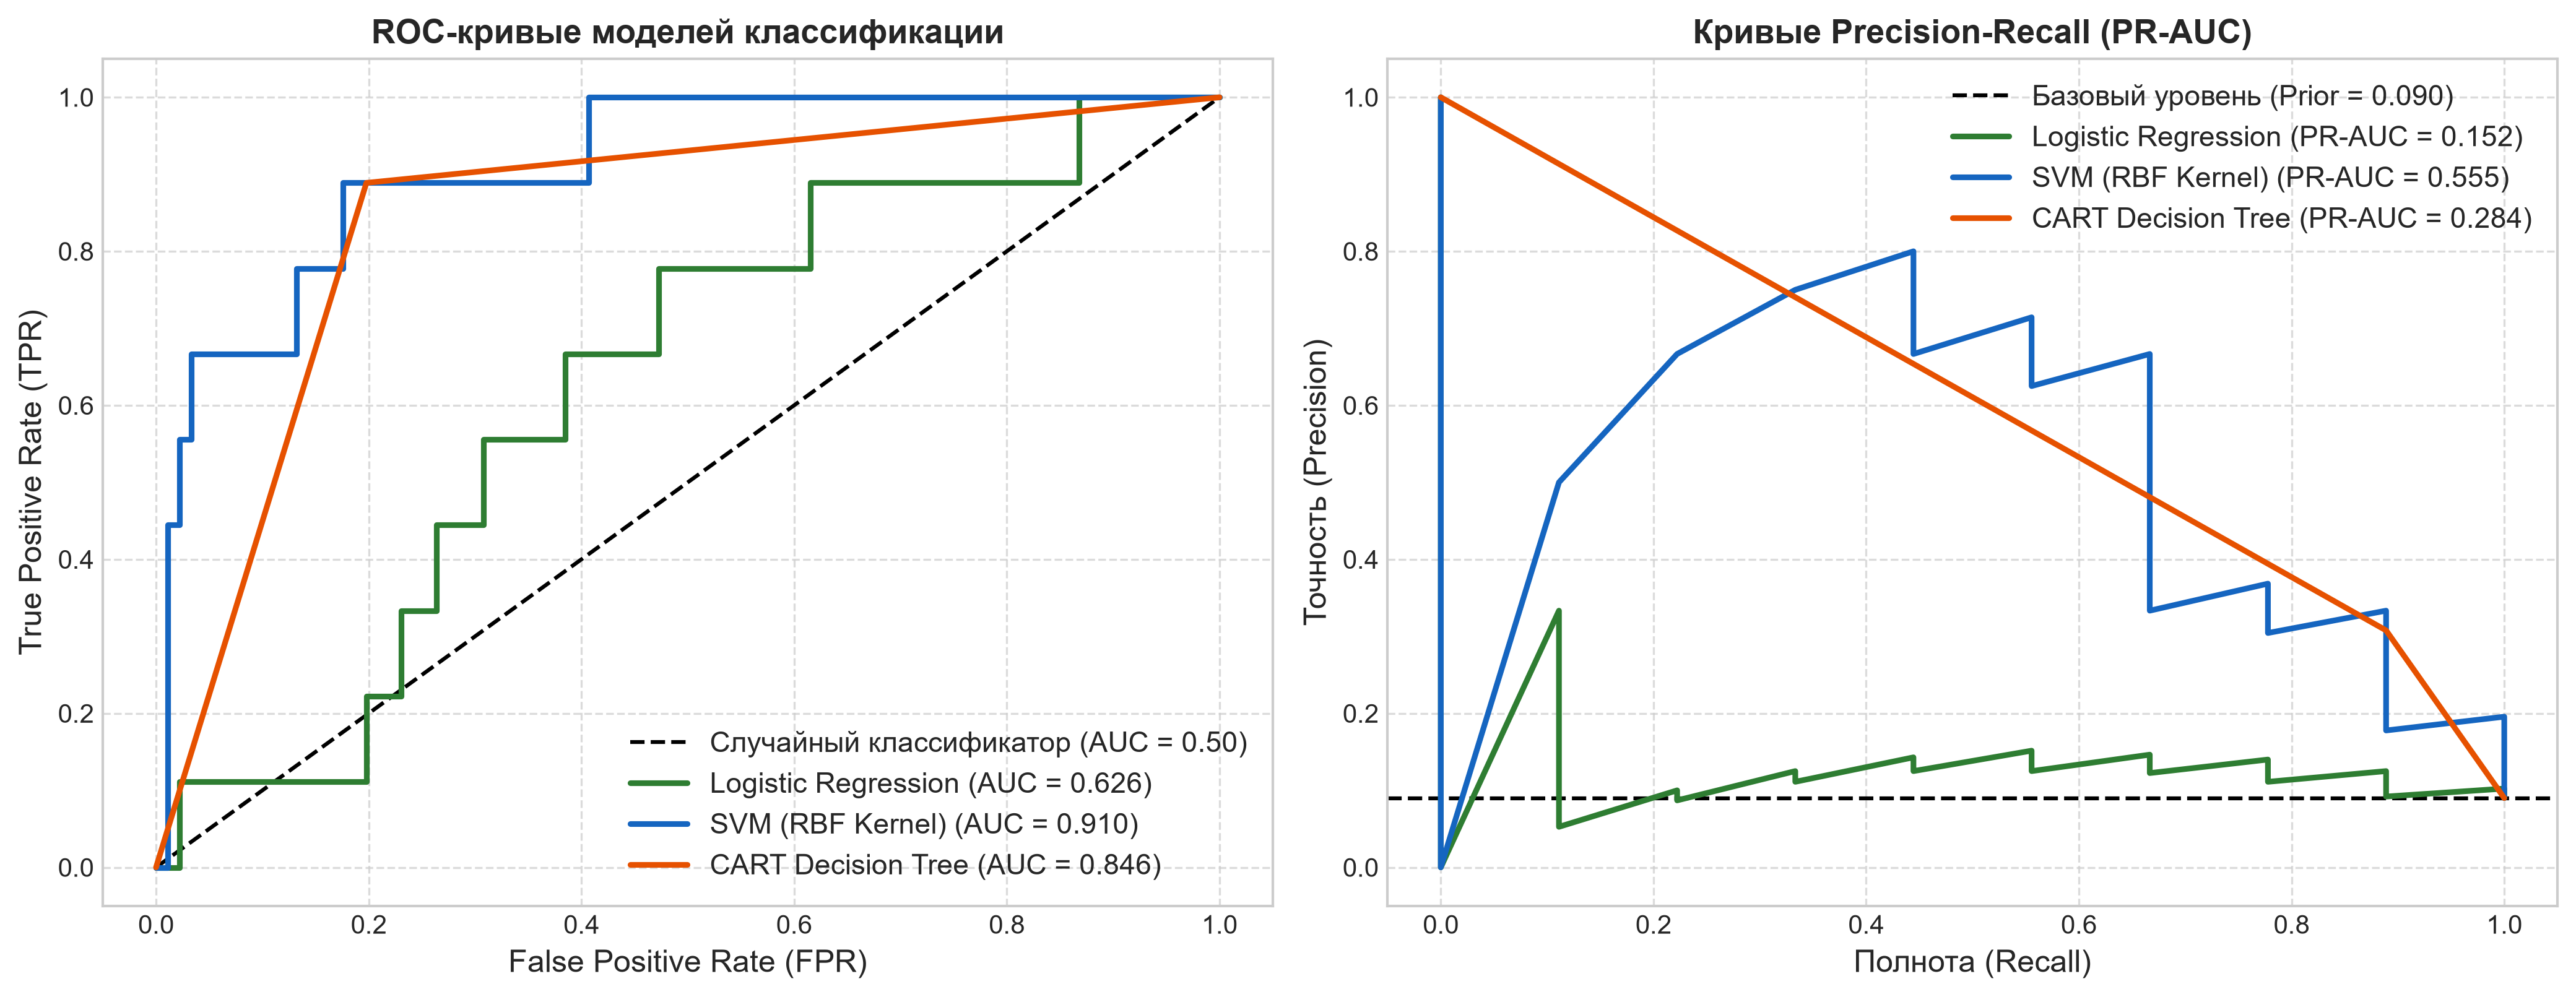

In [16]:
# Построение сравнительных кривых ROC-AUC и PR-AUC
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300)

# ROC
axes[0].plot([0, 1], [0, 1], "k--", lw=1.5, label="Случайный классификатор (AUC = 0.50)")
curves_info = [
    ("Logistic Regression", y_prob_custom_lr, "#2E7D32"),
    ("SVM (RBF Kernel)", y_prob_sk_rbf, "#1565C0"),
    ("CART Decision Tree", y_prob_sk_tree, "#E65100")
]

for label, probs, col in curves_info:
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_v = roc_auc_score(y_test, probs)
    axes[0].plot(fpr, tpr, color=col, lw=2.2, label=f"{label} (AUC = {auc_v:.3f})")

axes[0].set_title("ROC-кривые моделей классификации", fontweight="bold")
axes[0].set_xlabel("False Positive Rate (FPR)")
axes[0].set_ylabel("True Positive Rate (TPR)")
axes[0].legend(loc="lower right")
axes[0].grid(True, linestyle="--", alpha=0.7)

# PR
baseline = np.mean(y_test)
axes[1].axhline(y=baseline, color="black", linestyle="--", lw=1.5, label=f"Базовый уровень (Prior = {baseline:.3f})")

for label, probs, col in curves_info:
    prec, rec, _ = precision_recall_curve(y_test, probs)
    pr_auc = average_precision_score(y_test, probs)
    axes[1].plot(rec, prec, color=col, lw=2.2, label=f"{label} (PR-AUC = {pr_auc:.3f})")

axes[1].set_title("Кривые Precision-Recall (PR-AUC)", fontweight="bold")
axes[1].set_xlabel("Полнота (Recall)")
axes[1].set_ylabel("Точность (Precision)")
axes[1].legend(loc="upper right")
axes[1].grid(True, linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

In [17]:
# Сводная таблица всех метрик моделей
models_dict = {
    "Custom LogReg (Default)": (CustomLogisticRegression(class_weight=None).fit(X_train, y_train).predict(X_test),
                                CustomLogisticRegression(class_weight=None).fit(X_train, y_train).predict_proba(X_test)[:, 1]),
    "Custom LogReg (Balanced)": (y_pred_custom_lr, y_prob_custom_lr),
    "Sklearn LogReg (Balanced)": (y_pred_sk_lr, y_prob_sk_lr),
    "Custom Linear SVM": (y_pred_c_svm, 1.0 / (1.0 + np.exp(-custom_svm.decision_function(X_test)))),
    "Sklearn Linear SVM": (y_pred_sk_lin, sklearn_svm_lin.predict_proba(X_test)[:, 1]),
    "Sklearn SVM (RBF)": (y_pred_sk_rbf, y_prob_sk_rbf),
    "Custom CART (Gini)": (y_pred_c_tree, y_prob_c_tree),
    "Sklearn CART (Gini)": (y_pred_sk_tree, y_prob_sk_tree)
}

summary_rows = []
for m_name, (preds, probs) in models_dict.items():
    summary_rows.append({
        "Model": m_name,
        "Accuracy": accuracy_score(y_test, preds),
        "Balanced_Acc": balanced_accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds, zero_division=0),
        "F1_Score": f1_score(y_test, preds, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, probs),
        "PR_AUC": average_precision_score(y_test, probs)
    })

benchmark_df = pd.DataFrame(summary_rows)
print("ИТОГОВАЯ СВОДНАЯ ТАБЛИЦА СРАВНЕНИЯ МОДЕЛЕЙ:")
benchmark_df

ИТОГОВАЯ СВОДНАЯ ТАБЛИЦА СРАВНЕНИЯ МОДЕЛЕЙ:


,Model,Accuracy,Balanced_Acc,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
0,Custom LogReg (Default),0.91,0.500000,0.000000,0.000000,0.000000,0.623932,0.136634
1,Custom LogReg (Balanced),0.63,0.596459,0.131579,0.555556,0.212766,0.626374,0.151813
2,Sklearn LogReg (Balanced),0.63,0.596459,0.131579,0.555556,0.212766,0.627595,0.152401
3,Custom Linear SVM,0.57,0.663614,0.145833,0.777778,0.245614,0.653236,0.168710
4,Sklearn Linear SVM,0.63,0.646520,0.150000,0.666667,0.244898,0.612943,0.129025
5,Sklearn SVM (RBF),0.91,0.800366,0.500000,0.666667,0.571429,0.909646,0.555003
6,Custom CART (Gini),0.81,0.845543,0.307692,0.888889,0.457143,0.845543,0.283504
7,Sklearn CART (Gini),0.81,0.845543,0.307692,0.888889,0.457143,0.845543,0.283504


## 10. Итоговые выводы и контрольные вопросы к защите лабораторной работы

### 📌 Основные аналитические выводы:
1. **Проблема несбалансированных данных:** 
   В исходном датасете класс 1 («здоровые блюда») составляет всего 9.4% (47 из 500 записей). Модель с параметрами по умолчанию (Default LogReg) прогнозирует только доминирующий класс 0, получая кажущуюся высокой точность Accuracy = 0.9100, но при этом Recall = 0.0000 и F1 = 0.0000. Взвешивание классов (`class_weight='balanced'`) кардинально исправляет ситуацию, повышая Recall до 55.6% – 88.9%.
2. **Превосходство нелинейных моделей:** 
   Связь между макронутриентами и полезностью блюд носит нелинейный характер. Линейные модели (LogReg, Linear SVM) достигают ROC-AUC порядка 0.62–0.65, тогда как **SVM с RBF ядром** достигает **ROC-AUC = 0.9096** и **F1 = 0.5714**, а **дерево решений CART** достигает **ROC-AUC = 0.8455** и **Recall = 0.8889**.
3. **Регуляризация деревьев решений:**
   При неограниченной глубине дерево CART переобучается, теряя качество на отложенных данных. Оптимальной глубиной является $max\_depth = 4$, при которой достигается пик тестового F1-Score (0.4571) и ROC-AUC (0.8455).
4. **Математическая верификация реализации с нуля:**
   Кастомные классы `CustomLogisticRegression`, `CustomLinearSVM` и `CustomDecisionTree`, разработанные на базе чистого NumPy, показали полное совпадение ключевых метрик с промышленными эталонами Scikit-Learn.

---

### 🎓 Шпаргалка: Топ-5 вопросов преподавателя на защите
1. **Вопрос:** *Почему метрика Accuracy неприменима в качестве единственного критерия в данной задаче?*  
   **Ответ:** Из-за дисбаланса 9.4% к 90.6%. Трюковой классификатор, всегда выдающий класс 0, получит Accuracy = 90.6%, но не обнаружит ни одного здорового блюда ($TP=0, Recall=0$). Необходимы метрики F1-Score, Balanced Accuracy, ROC-AUC и PR-AUC.
2. **Вопрос:** *Как работает логистическая регрессия и почему в ней используется сигмоида?*  
   **Ответ:** Сигмоида $\sigma(z) = \frac{1}{1 + e^{-z}}$ монотонно сжимает линейную комбинацию $z = w^T x + b \in (-\infty, +\infty)$ в диапазон $(0, 1)$, что математически интерпретируется как апостериорная вероятность $P(y=1 \mid x)$.
3. **Вопрос:** *В чем состоит принцип максимального зазора в SVM? Что такое опорные векторы?*  
   **Ответ:** SVM максимизирует геометрический зазор $M = \frac{2}{\|w\|_2}$ между разделяющей гиперплоскостью и ближайшими точками классов. Опорные векторы — это именно те точки выборки, которые лежат на границе зазора (отступ $y_i (w^T x_i + b) \le 1$). Только они определяют ориентацию гиперплоскости; остальные точки не влияют на $w$.
4. **Вопрос:** *По какому критерию CART выбирает наилучшее разбиение в узле?*  
   **Ответ:** По критерию максимизации прироста информации (Information Gain):
   $Q(X_m, j, t) = H(X_m) - \frac{|X_l|}{|X_m|} H(X_l) - \frac{|X_r|}{|X_m|} H(X_r)$, где $H$ — критерий информативности (индекс Джини $G = 1 - \sum p_k^2$ или энтропия Шеннона $-\sum p_k \log_2 p_k$).
5. **Вопрос:** *Как предотвратить Data Leakage при масштабировании данных?*  
   **Ответ:** Разделение выборки на Train/Test производится строго **до** масштабирования. Параметры скейлера ($\mu$ и $\sigma$) вычисляются исключительно на обучающей выборке (`scaler.fit(X_train)`), а на тестовой выборке выполняется только применение этих параметров (`scaler.transform(X_test)`).